# 3.03 — Data drift and model performance

Issue [#42](https://github.com/CarlosHeinze/MLOps_Team2/issues/42) · [ML Canvas §10](../references/ml-canvas.md#10-monitoring)

Use the same model loader, forecast path and evaluation metrics as the service and Phase 2.
Keep the validation reference and monitoring windows disjoint. For injected scenarios,
the clean copy of the same window controls for calendar and membership differences.

The default uses a small deterministic **synthetic** dataset, two local LightGBM models fit
on synthetic training hours and a private SQLite MLflow store. Set the kernel environment
variable `MIBICI_MONITOR_HISTORICAL=1` to load the team's feature snapshot and both exported
champions. Use `MIBICI_MONITOR_TRACK=0` for offline reports, or start `make mlflow` for tracked
historical runs. See the [verification notes](../docs/monitoring.md).

In [1]:
import os
from pathlib import Path
import sys
from tempfile import mkdtemp

from IPython.display import Image, display
import mlflow
import pandas as pd

from team2_mlops2026 import monitoring as mon, tracking
from team2_mlops2026.config import PROJ_ROOT
from team2_mlops2026.serving.app import load_models

historical = os.getenv("MIBICI_MONITOR_HISTORICAL") == "1"
tracked = os.getenv("MIBICI_MONITOR_TRACK", "1") == "1"
if historical:
    src, dst = mon.FEATURES_DIR, mon.MONITORING_DIR
    loaded = load_models()
    months = (mon.TEST_START, mon.SIM_MONTH, mon.REAL_MONTH)
    data_kind = "historical"
else:
    sys.path.insert(0, str(PROJ_ROOT / "tests"))
    from monitoring_factory import REFERENCE_MONTH, REPLAY_MONTH, SIM_MONTH, write_fixture

    demo_dir = mon.MONITORING_DIR.with_name("monitoring-demo")
    demo_dir.mkdir(parents=True, exist_ok=True)
    work = Path(mkdtemp(prefix="demo-", dir=demo_dir))
    src, models = write_fixture(work)
    dst = work / "reports"
    loaded = load_models(models_dir=models)
    months = (REFERENCE_MONTH, SIM_MONTH, REPLAY_MONTH)
    data_kind = "synthetic"
    if tracked:
        tracking.MLFLOW_TRACKING_URI = f"sqlite:///{(work / 'mlflow.db').as_posix()}"
        tracking.MLFLOW_EXPERIMENT_NAME = "mibici-monitoring-demo"
        mlflow.set_tracking_uri(tracking.MLFLOW_TRACKING_URI)
        mlflow.create_experiment(
            tracking.MLFLOW_EXPERIMENT_NAME, artifact_location=(work / "artifacts").as_uri()
        )

print(f"Source: {data_kind}; reference, control, unmodified replay: {months}")
display(pd.Series(vars(mon.DEFAULT_THRESHOLDS), name="Operational threshold"))

Source: synthetic; reference, control, unmodified replay: ('2026-03', '2026-04', '2026-05')


psi_warning         0.100
psi_alert           0.250
missing_increase    0.100
unknown_share       0.100
min_improvement     0.100
peak_departures     0.604
peak_arrivals       0.561
Name: Operational threshold, dtype: float64

## Monitoring run

PSI compares binned shares, including missing values. KS reports the maximum difference
between empirical CDFs among observed values. The p-value is descriptive for correlated
station-hours. The alerts use the PSI thresholds and data-quality rules in the canvas.

The tables compare the held-out reference, the monitoring case and the best existing
same-window baseline in each target. Delta uses the clean copy for simulations and the
held-out reference for the unmodified replay. Positive WAPE delta is a loss. The
degradation flag also requires the corresponding performance threshold to be crossed.
The scenario table uses the default 25% severity for its leading signals. All levels are
recorded in the individual CSV files and MLflow runs.

In [2]:
run_monitor = mon.monitor_tracked if tracked else mon.monitor
summaries = run_monitor(
    src, dst, loaded=loaded, reference_month=months[0], sim_month=months[1],
    real_month=months[2], severities=(0.10, 0.25, 0.50), data_kind=data_kind,
)

overview = pd.DataFrame([
    {
        "scenario": case["scenario"],
        "severity": case["scenario_params"]["severity"],
        "target": target,
        "reference WAPE": case["scores"]["reference"][target]["peak_wape"],
        "monitor WAPE": metrics["peak_wape"],
        "best baseline": metrics["baseline"],
        "baseline WAPE": metrics["baseline_peak_wape"],
        "improvement": metrics["improvement"],
        "WAPE delta": case["alerts"]["performance"][target]["peak_wape_delta"],
        "degraded": case["alerts"]["performance"][target]["performance_degraded"],
        "level": case["alerts"]["level"],
    }
    for case in summaries for target, metrics in case["scores"]["monitoring"].items()
]).set_index(["scenario", "severity", "target"])

selected = {
    case["scenario"]: case for case in summaries
    if case["scenario_params"]["severity"] in (0.0, 0.25)
}
signals = {
    scenario: pd.read_csv(dst / case["name"] / "drift.csv", index_col="feature")
    .drop(index=["month_sin", "month_cos"]).nlargest(4, "psi")
    for scenario, case in selected.items()
}

print(f"{len(summaries)} cases written to {dst.relative_to(PROJ_ROOT)}")

2026-11-22 14:59:09.294 | INFO     | team2_mlops2026.monitoring:monitor:823 - drift-control-0: ok — Continue routine monitoring.


2026-11-22 14:59:10.337 | INFO     | team2_mlops2026.monitoring:monitor:823 - drift-mean-shift-0.1: alert — Keep watching the shifted distributions and forecast error.


2026-11-22 14:59:11.691 | INFO     | team2_mlops2026.monitoring:monitor:823 - drift-mean-shift-0.25: alert — Keep watching the shifted distributions and forecast error.


2026-11-22 14:59:13.167 | INFO     | team2_mlops2026.monitoring:monitor:823 - drift-mean-shift-0.5: alert — Keep watching the shifted distributions and forecast error.


2026-11-22 14:59:14.136 | INFO     | team2_mlops2026.monitoring:monitor:823 - drift-covariate-only-0.1: alert — Keep watching the shifted distributions and forecast error.


2026-11-22 14:59:15.376 | INFO     | team2_mlops2026.monitoring:monitor:823 - drift-covariate-only-0.25: alert — Keep watching the shifted distributions and forecast error.


... (8 outputs left out)

2026-11-22 14:59:22.873 | INFO     | team2_mlops2026.monitoring:monitor:823 - drift-new-stations-0.25: alert — Review the feature pipeline and data contract, then replay the window.


2026-11-22 14:59:23.670 | INFO     | team2_mlops2026.monitoring:monitor:823 - drift-new-stations-0.5: alert — Review the feature pipeline and data contract, then replay the window.


2026-11-22 14:59:25.316 | INFO     | team2_mlops2026.monitoring:monitor:823 - drift-real-0: alert — Review the feature pipeline and data contract, then replay the window.


17 cases written to data/processed/mibici/monitoring-demo/demo-eu2qogm1/reports


## Control

The unmodified simulation window. Its comparison with the reference shows natural window differences, and its paired performance delta is zero.

In [3]:
scenario = 'control'
display(overview.loc[scenario].round(4))
display(signals[scenario].round(4))
print(f"{selected[scenario]['alerts']['level']} → {selected[scenario]['alerts']['action']}")

reference WAPE  monitor WAPE       best baseline  \
severity target                                                         
0.0      departures          0.0040        0.0043  historical_average   
         arrivals            0.0057        0.0063  historical_average   

                     baseline WAPE  improvement  WAPE delta  degraded level  
severity target                                                              
0.0      departures         0.3916       0.9890         0.0     False    ok  
         arrivals           0.3577       0.9823         0.0     False    ok

,psi,ks,ks_pvalue,reference_missing,monitoring_missing,missing_increase,psi_vs_control
feature,,,,,,,
weekday,0.0355,0.0559,0.0000,0.0,0.0,0.0,0.0
forecast_arrivals,0.0029,0.0221,0.1598,0.0,0.0,0.0,0.0
forecast_departures,0.0026,0.0184,0.3446,0.0,0.0,0.0,0.0
actual_departures,0.0010,0.0159,0.5264,0.0,0.0,0.0,0.0


ok → Continue routine monitoring.


## Mean shift

Increase both lagged demand and observed counts. Counts are rounded to integers.

In [4]:
scenario = 'mean-shift'
display(overview.loc[scenario].round(4))
display(signals[scenario].round(4))
print(f"{selected[scenario]['alerts']['level']} → {selected[scenario]['alerts']['action']}")

reference WAPE  monitor WAPE       best baseline  \
severity target                                                         
0.10     departures          0.0040        0.0207  historical_average   
         arrivals            0.0057        0.0632  historical_average   
0.25     departures          0.0040        0.0501  historical_average   
         arrivals            0.0057        0.1262  historical_average   
0.50     departures          0.0040        0.1035  historical_average   
         arrivals            0.0057        0.1816  historical_average   

                     baseline WAPE  improvement  WAPE delta  degraded  level  
severity target                                                               
0.10     departures         0.3867       0.9465      0.0164     False  alert  
         arrivals           0.3497       0.8191      0.0569     False  alert  
0.25     departures         0.3933       0.8726      0.0458     False  alert  
         arrivals           0.3538       0.6433      0.1199     False  alert  
0.50     departures         0.3979       0.7400      0.0991     False  alert  
         arrivals           0.3786       0.5204      0.1752     False  alert

,psi,ks,ks_pvalue,reference_missing,monitoring_missing,missing_increase,psi_vs_control
feature,,,,,,,
arrivals_mean_7d,12.2890,0.6906,0.0,0.0,0.0,0.0,12.2861
arrivals_same_hour_4w,8.9574,0.6845,0.0,0.0,0.0,0.0,8.9574
departures_mean_7d,8.0438,0.4435,0.0,0.0,0.0,0.0,8.0427
actual_arrivals,6.2281,0.4225,0.0,0.0,0.0,0.0,5.7135


alert → Keep watching the shifted distributions and forecast error.


## Covariate-only shift

Inflate demand inputs while holding observed counts fixed to simulate a faulty aggregation.

In [5]:
scenario = 'covariate-only'
display(overview.loc[scenario].round(4))
display(signals[scenario].round(4))
print(f"{selected[scenario]['alerts']['level']} → {selected[scenario]['alerts']['action']}")

reference WAPE  monitor WAPE       best baseline  \
severity target                                                         
0.10     departures          0.0040        0.0962  historical_average   
         arrivals            0.0057        0.0562  historical_average   
0.25     departures          0.0040        0.2366  historical_average   
         arrivals            0.0057        0.1705  historical_average   
0.50     departures          0.0040        0.3722  historical_average   
         arrivals            0.0057        0.3029  historical_average   

                     baseline WAPE  improvement  WAPE delta  degraded  level  
severity target                                                               
0.10     departures         0.3916       0.7543      0.0919     False  alert  
         arrivals           0.3577       0.8430      0.0498     False  alert  
0.25     departures         0.3916       0.3957      0.2323     False  alert  
         arrivals           0.3577       0.5234      0.1642     False  alert  
0.50     departures         0.3916       0.0496      0.3678      True  alert  
         arrivals           0.3577       0.1533      0.2966     False  alert

,psi,ks,ks_pvalue,reference_missing,monitoring_missing,missing_increase,psi_vs_control
feature,,,,,,,
arrivals_mean_7d,12.2890,0.6906,0.0,0.0,0.0,0.0,12.2861
arrivals_same_hour_4w,8.9574,0.6845,0.0,0.0,0.0,0.0,8.9574
departures_mean_7d,8.0438,0.4435,0.0,0.0,0.0,0.0,8.0427
departures_same_hour_4w,6.1616,0.4286,0.0,0.0,0.0,0.0,6.1616


alert → Keep watching the shifted distributions and forecast error.


## Missing features

Mask profile scores, lag history and station attributes for seeded station subsets. The decision metric uses carried-through capacity for a like-for-like check.

In [6]:
scenario = 'missing-features'
display(overview.loc[scenario].round(4))
display(signals[scenario].round(4))
print(f"{selected[scenario]['alerts']['level']} → {selected[scenario]['alerts']['action']}")

reference WAPE  monitor WAPE       best baseline  \
severity target                                                         
0.10     departures          0.0040        0.0599  historical_average   
         arrivals            0.0057        0.0570  historical_average   
0.25     departures          0.0040        0.1152  historical_average   
         arrivals            0.0057        0.1073  historical_average   
0.50     departures          0.0040        0.2257  historical_average   
         arrivals            0.0057        0.2082  historical_average   

                     baseline WAPE  improvement  WAPE delta  degraded  level  
severity target                                                               
0.10     departures         0.3916       0.8471      0.0556     False  alert  
         arrivals           0.3577       0.8406      0.0507     False  alert  
0.25     departures         0.3916       0.7059      0.1109     False  alert  
         arrivals           0.3577       0.7001      0.1009     False  alert  
0.50     departures         0.3916       0.4235      0.2214     False  alert  
         arrivals           0.3577       0.4181      0.2018     False  alert

,psi,ks,ks_pvalue,reference_missing,monitoring_missing,missing_increase,psi_vs_control
feature,,,,,,,
latitude,6.9806,0.1429,0.0,0.0,0.2857,0.2857,6.9806
longitude,6.9806,0.1429,0.0,0.0,0.2857,0.2857,6.9806
capacity,6.9806,0.1429,0.0,0.0,0.2857,0.2857,6.9806
pc1,6.9806,0.1714,0.0,0.0,0.2857,0.2857,6.9806


alert → Review the feature pipeline and data contract, then replay the window.


## Seasonal shift

Reduce weekday peak demand to approximate holiday conditions. Change lag inputs at their own historical hours and approximate the effect on rolling means.

In [7]:
scenario = 'seasonal'
display(overview.loc[scenario].round(4))
display(signals[scenario].round(4))
print(f"{selected[scenario]['alerts']['level']} → {selected[scenario]['alerts']['action']}")

reference WAPE  monitor WAPE       best baseline  \
severity target                                                         
0.10     departures          0.0040        0.0566  historical_average   
         arrivals            0.0057        0.0833  historical_average   
0.25     departures          0.0040        0.1645  historical_average   
         arrivals            0.0057        0.2314  historical_average   
0.50     departures          0.0040        0.4724      seasonal_naive   
         arrivals            0.0057        0.5624      seasonal_naive   

                     baseline WAPE  improvement  WAPE delta  degraded  level  
severity target                                                               
0.10     departures         0.3976       0.8578      0.0522     False  alert  
         arrivals           0.3678       0.7735      0.0770     False  alert  
0.25     departures         0.4019       0.5907      0.1602     False  alert  
         arrivals           0.3858       0.4001      0.2251     False  alert  
0.50     departures         0.7885       0.4009      0.4681     False  alert  
         arrivals           0.7108       0.2087      0.5561      True  alert

,psi,ks,ks_pvalue,reference_missing,monitoring_missing,missing_increase,psi_vs_control
feature,,,,,,,
arrivals_same_hour_4w,1.5699,0.1310,0.0,0.0,0.0,0.0,1.5699
departures_same_hour_4w,0.7639,0.0960,0.0,0.0,0.0,0.0,0.7639
arrivals_mean_7d,0.7348,0.1903,0.0,0.0,0.0,0.0,0.7343
departures_mean_7d,0.5783,0.1130,0.0,0.0,0.0,0.0,0.5778


alert → Keep watching the shifted distributions and forecast error.


## New stations

Replace selected station IDs with unseen IDs and clear lag and profile history. Score the cold-start stations with existing model and baseline behavior.

In [8]:
scenario = 'new-stations'
display(overview.loc[scenario].round(4))
display(signals[scenario].round(4))
print(f"{selected[scenario]['alerts']['level']} → {selected[scenario]['alerts']['action']}")

reference WAPE  monitor WAPE       best baseline  \
severity target                                                         
0.10     departures          0.0040        0.0596  historical_average   
         arrivals            0.0057        0.0566  historical_average   
0.25     departures          0.0040        0.1149  historical_average   
         arrivals            0.0057        0.1068  historical_average   
0.50     departures          0.0040        0.2258  historical_average   
         arrivals            0.0057        0.2081  historical_average   

                     baseline WAPE  improvement  WAPE delta  degraded  level  
severity target                                                               
0.10     departures         0.3916       0.8479      0.0553     False  alert  
         arrivals           0.3577       0.8419      0.0502     False  alert  
0.25     departures         0.3916       0.7065      0.1106     False  alert  
         arrivals           0.3577       0.7013      0.1005     False  alert  
0.50     departures         0.3916       0.4235      0.2214     False  alert  
         arrivals           0.3577       0.4184      0.2017     False  alert

,psi,ks,ks_pvalue,reference_missing,monitoring_missing,missing_increase,psi_vs_control
feature,,,,,,,
pc1,6.9806,0.1714,0.0,0.0,0.2857,0.2857,6.9806
departures_same_hour_4w,6.8337,0.1643,0.0,0.0,0.2857,0.2857,6.8337
departures_lag_7d,6.8294,0.0748,0.0,0.0,0.2857,0.2857,5.2091
station_id,6.7826,NaN,NaN,0.0,0.0000,0.0000,6.7826


alert → Review the feature pipeline and data contract, then replay the window.


## Unmodified replay

With the team snapshot this is September 2026. With the demonstration dataset it is May 2026 **synthetic** data, replayed as generated. The real-data comparison requires the historical snapshot.

In [9]:
scenario = 'real'
display(overview.loc[scenario].round(4))
display(signals[scenario].round(4))
print(f"{selected[scenario]['alerts']['level']} → {selected[scenario]['alerts']['action']}")

reference WAPE  monitor WAPE       best baseline  \
severity target                                                         
0.0      departures          0.0040        0.0683  historical_average   
         arrivals            0.0057        0.1435  historical_average   

                     baseline WAPE  improvement  WAPE delta  degraded  level  
severity target                                                               
0.0      departures         0.4011       0.8297      0.0643     False  alert  
         arrivals           0.3703       0.6125      0.1378     False  alert

,psi,ks,ks_pvalue,reference_missing,monitoring_missing,missing_increase
feature,,,,,,
arrivals_mean_7d,10.2063,0.6849,0.0,0.0,0.0081,0.0081
departures_mean_7d,6.9402,0.4951,0.0,0.0,0.0081,0.0081
actual_arrivals,5.3610,0.4398,0.0,0.0,0.0000,0.0000
actual_departures,3.9080,0.3806,0.0,0.0,0.0000,0.0000


alert → Review the feature pipeline and data contract, then replay the window.


## Result → action

Read the quality, drift and performance evidence together. The missing-feature alert asks
for pipeline review. The retraining recommendation requires a measured loss with drift and
uses the Phase 2 backtest as the promotion gate. With distribution drift and stable
performance, continue monitoring. The replay and its source are labeled in every run.

,feature drift,forecast drift,quality,degraded,level,action
case,,,,,,
drift-control-0,False,False,False,False,ok,Continue routine monitoring.
drift-mean-shift-0.1,True,True,False,False,alert,Keep watching the shifted distributions and fo...
drift-mean-shift-0.25,True,True,False,False,alert,Keep watching the shifted distributions and fo...
drift-mean-shift-0.5,True,True,False,False,alert,Keep watching the shifted distributions and fo...
drift-covariate-only-0.1,True,True,False,False,alert,Keep watching the shifted distributions and fo...
drift-covariate-only-0.25,True,True,False,False,alert,Keep watching the shifted distributions and fo...
drift-covariate-only-0.5,True,True,False,True,alert,"Confirm the loss with observed labels, then co..."
drift-missing-features-0.1,True,True,True,False,alert,"Review the feature pipeline and data contract,..."
drift-missing-features-0.25,True,True,True,False,alert,"Review the feature pipeline and data contract,..."


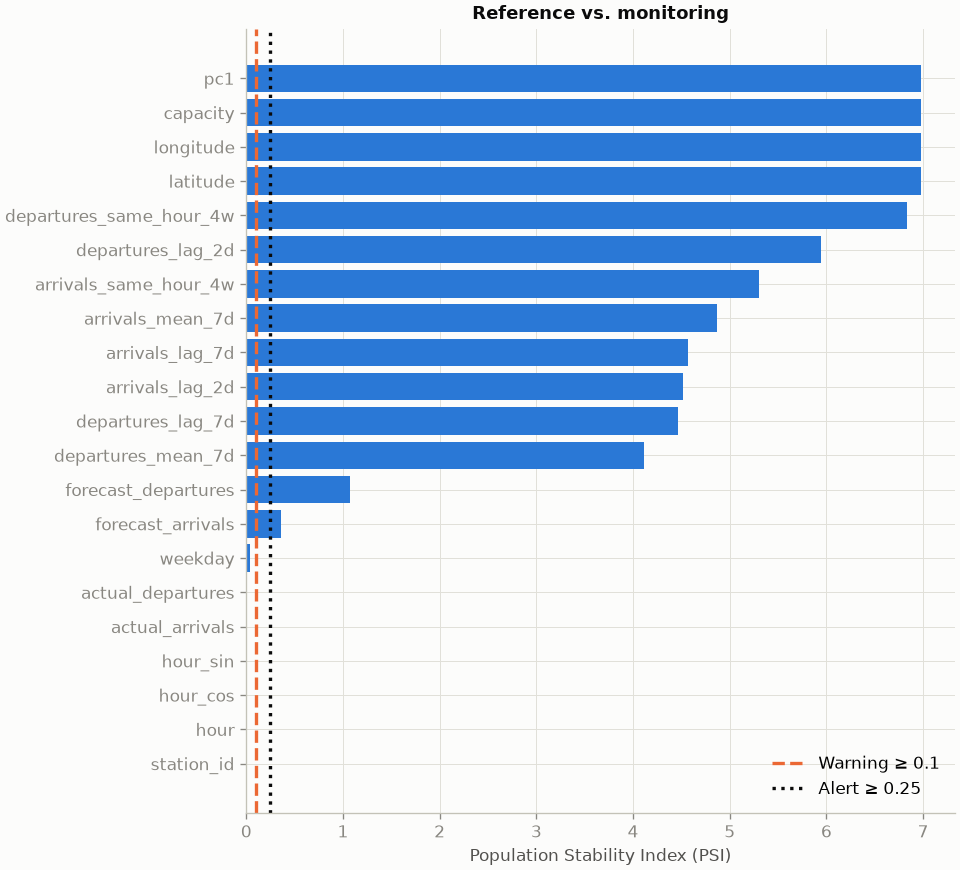

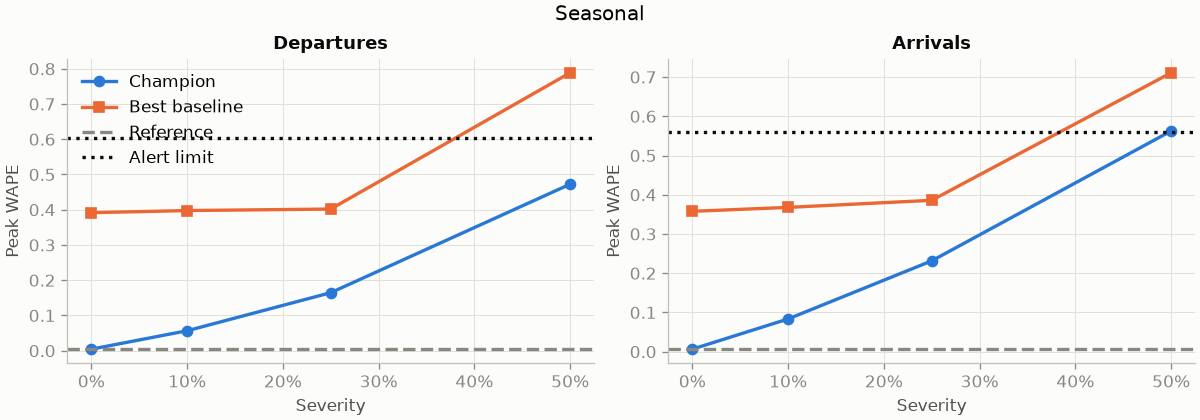

In [10]:
actions = pd.DataFrame([
    {
        "case": case["name"],
        "feature drift": bool(case["alerts"]["feature_drift"]),
        "forecast drift": bool(case["alerts"]["prediction_drift"]),
        "quality": case["alerts"]["quality_alert"],
        "degraded": any(t["performance_degraded"] for t in case["alerts"]["performance"].values()),
        "level": case["alerts"]["level"],
        "action": case["alerts"]["action"],
    }
    for case in summaries
]).set_index("case")
display(actions)
display(Image(filename=dst / selected["missing-features"]["name"] / "psi.png"))
display(Image(filename=dst / "seasonal-performance.png"))